# **Lab 7(B) - Mathematical and Statistical Filters**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

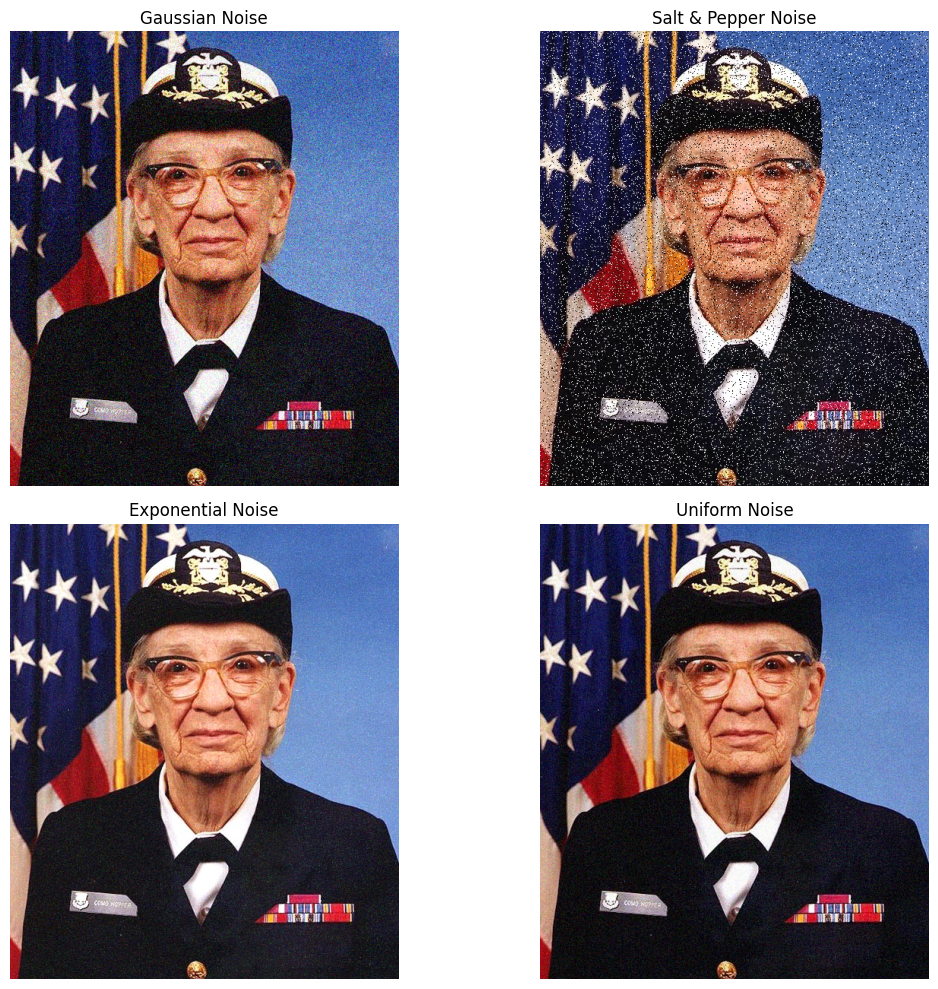

In [2]:
np.random.seed(0)
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
imgPath = 'color_image.jpg'   # COLOUR image
img = cv2.cvtColor(cv2.imread(imgPath), cv2.COLOR_BGR2RGB)

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape[:2]
    shp = image.shape   # (row, col, 3) for colour images

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, shp)
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape[:2]]
        noisy[tuple(coords)] = 255      # all colour channels -> white pixel
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape[:2]]
        noisy[tuple(coords)] = 0        # all colour channels -> black pixel
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=shp)
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, shp)
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)



# 2. Original colour image (RGB)

# 3. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 4. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()


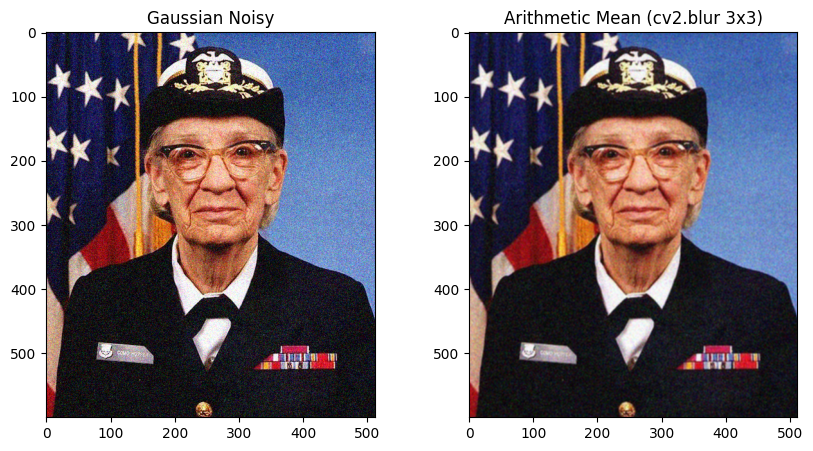

In [3]:
# --- METHOD 1: Using Built-in OpenCV function ---

# Arithmetic Mean Filter (3x3 window). Increase to (5,5), (7,7) ... for more smoothing.
filtered_img = cv2.blur(noise_gauss, (3, 3))

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_gauss), plt.title('Gaussian Noisy')
plt.subplot(122), plt.imshow(filtered_img), plt.title('Arithmetic Mean (cv2.blur 3x3)')
plt.show()

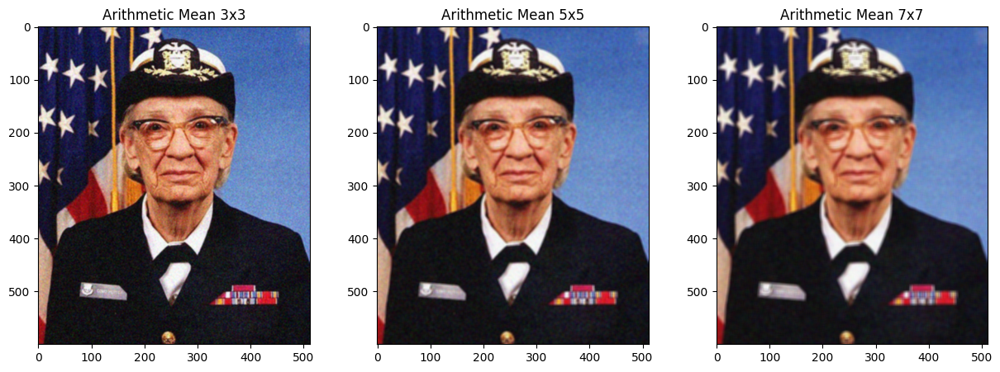

In [4]:
# Effect of the window size on the Gaussian-noisy image
plt.figure(figsize=(15, 5))
for i, k in enumerate([3, 5, 7]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.blur(noise_gauss, (k, k)))
    plt.title(f'Arithmetic Mean {k}x{k}')
plt.show()

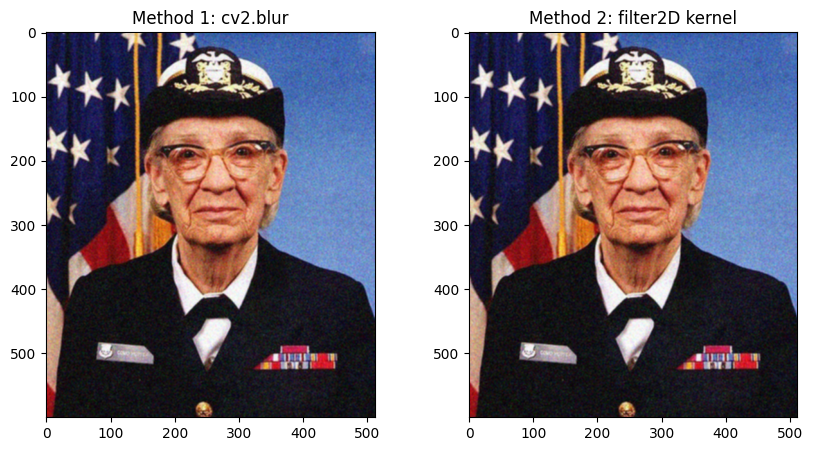

Max difference between the two methods: 0


In [5]:
# --- METHOD 2: Manual implementation using a Kernel ---

# Arithmetic-mean kernel = matrix of 1s divided by the number of pixels.
# NOTE: it must be applied to the NOISY image (the original template used the clean image).
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(filtered_img), plt.title('Method 1: cv2.blur')
plt.subplot(122), plt.imshow(arithmetic_mean_manual), plt.title('Method 2: filter2D kernel')
plt.show()

print("Max difference between the two methods:", np.abs(filtered_img.astype(int) - arithmetic_mean_manual.astype(int)).max())

## **Geometric Means**

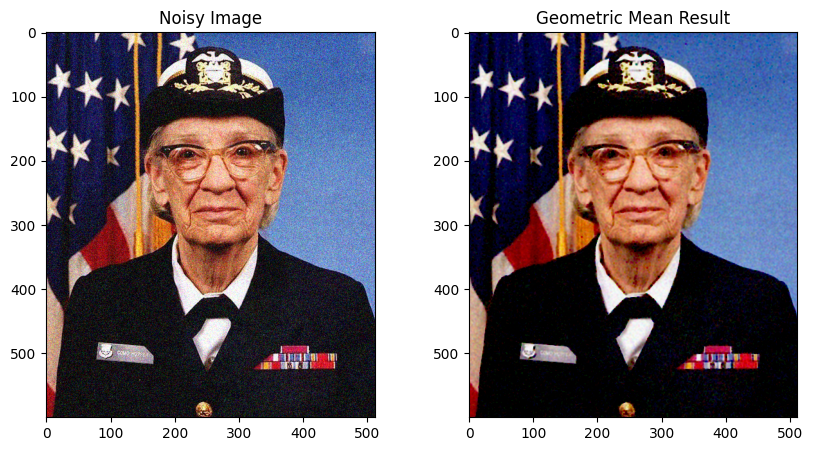

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result), plt.title('Geometric Mean Result')
plt.show()


## **Harmonic Means Filter**

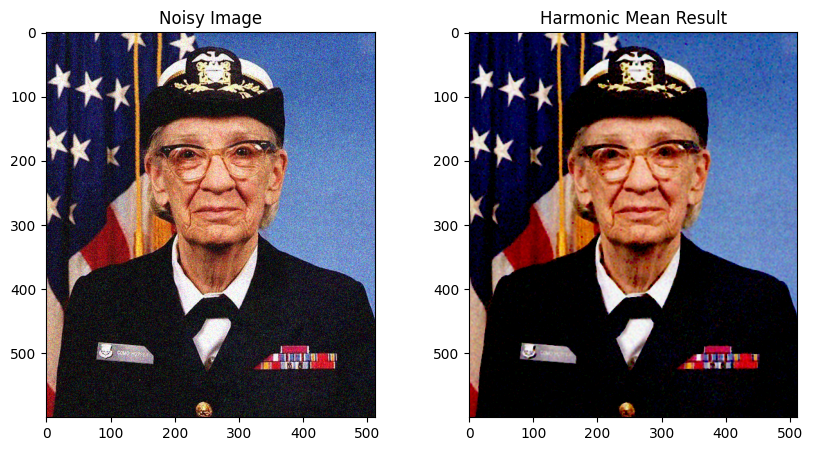

In [7]:

def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img), plt.title('Harmonic Mean Result')
plt.show()


## **Contra - Harmonic Mean Filter**

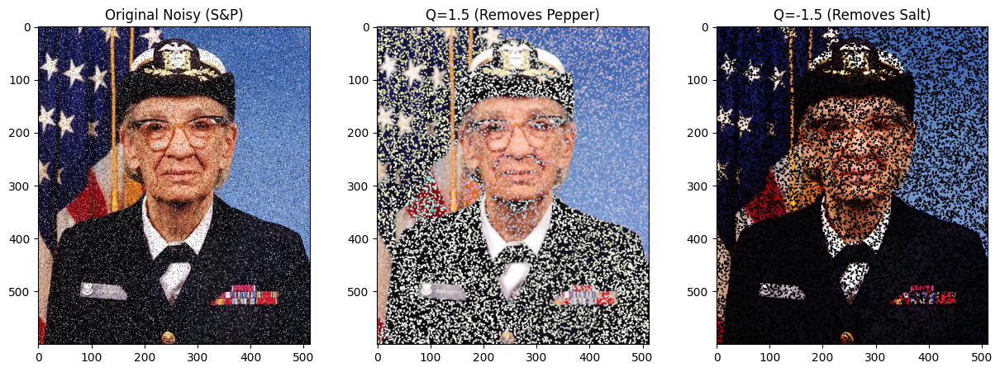

In [8]:


def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp   # contra-harmonic is meant for salt & pepper noise

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img), plt.title('Original Noisy (S&P)')
plt.subplot(132), plt.imshow(pepper_removed), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed), plt.title('Q=-1.5 (Removes Salt)')
plt.show()


## **Median Filter**

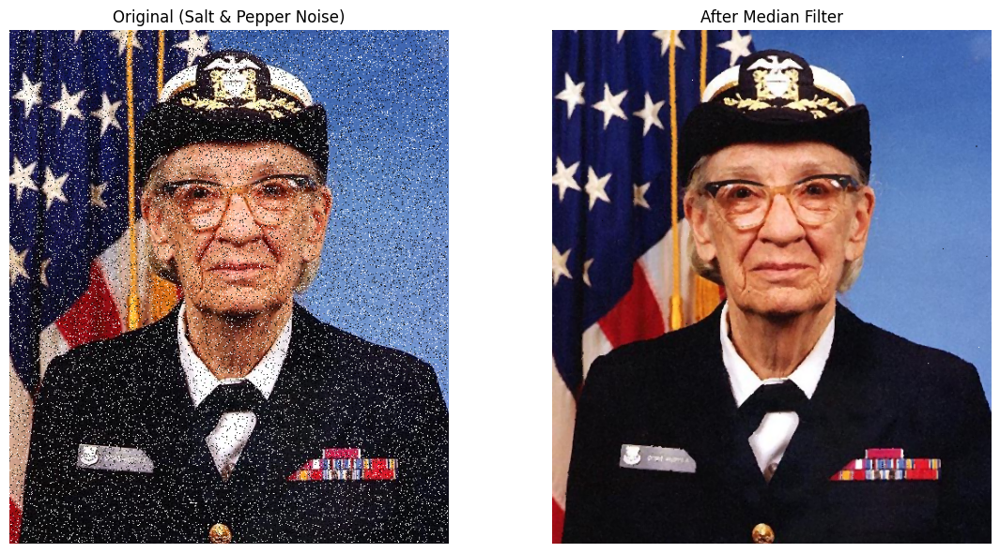

In [9]:



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp

# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Max and Min Filter**

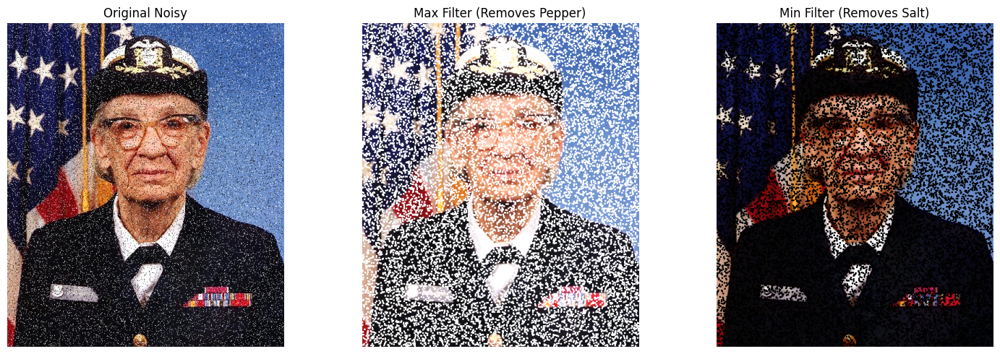

In [10]:


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp



# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))

plt.subplot(131), plt.imshow(noise_img), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Mid-Point Filtering**

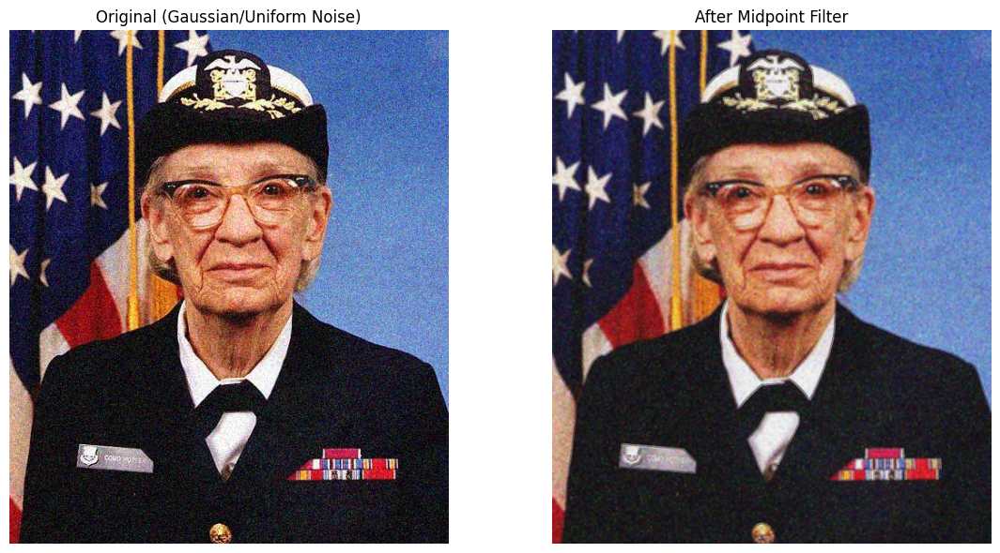

In [11]:

def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img), plt.title('Original (Gaussian/Uniform Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()


## **Applying the filters on the provided Salt & Pepper images**

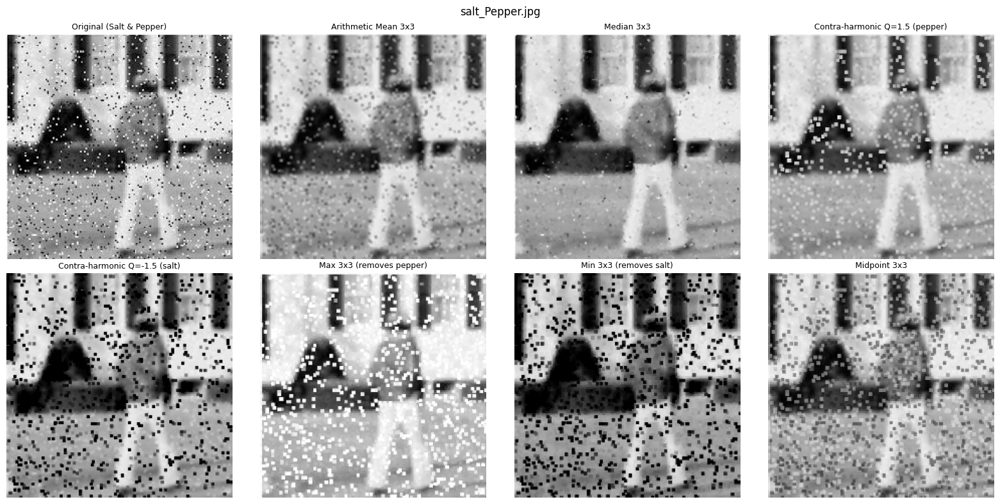

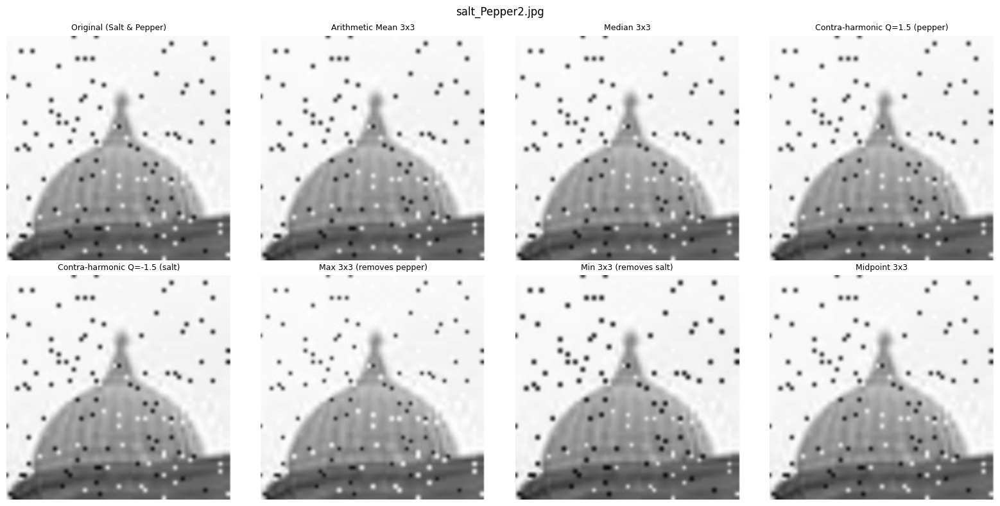

In [12]:
# ========== Apply the filters on the provided Salt & Pepper images ==========
import os

def show_sp(path, title):
    im = cv2.imread(path, 0)
    results = {
        'Original (Salt & Pepper)': im,
        'Arithmetic Mean 3x3': cv2.blur(im, (3, 3)),
        'Median 3x3': cv2.medianBlur(im, 3),
        'Contra-harmonic Q=1.5 (pepper)': contra_harmonic_mean(im, 3, 1.5),
        'Contra-harmonic Q=-1.5 (salt)': contra_harmonic_mean(im, 3, -1.5),
        'Max 3x3 (removes pepper)': cv2.dilate(im, np.ones((3, 3), np.uint8)),
        'Min 3x3 (removes salt)': cv2.erode(im, np.ones((3, 3), np.uint8)),
        'Midpoint 3x3': midpoint_filter(im, 3),
    }
    plt.figure(figsize=(16, 8))
    for i, (name, r) in enumerate(results.items()):
        plt.subplot(2, 4, i + 1), plt.imshow(r, cmap='gray', vmin=0, vmax=255), plt.title(name, fontsize=9), plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_sp('salt_Pepper.jpg', 'salt_Pepper.jpg')
show_sp('salt_Pepper2.jpg', 'salt_Pepper2.jpg')

## Summary
| Filter | Best for |
|---|---|
| Arithmetic mean | Gaussian / uniform noise (blurs edges) |
| Geometric mean | Gaussian noise, preserves detail better than arithmetic mean |
| Harmonic mean | Salt noise and Gaussian noise (fails on pepper) |
| Contra-harmonic Q>0 / Q<0 | Pepper noise / salt noise (one type only) |
| Median | Salt & pepper (best overall) |
| Max / Min | Pepper only / salt only |
| Midpoint | Gaussian and uniform noise |